# Import Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import networkx as nx

In [3]:
mg1655_expression = pd.read_csv("precise_mg1655_all/precise_mg1655-log_tpm_expression.csv")

In [4]:
mg1655_network_interactions = pd.read_csv(
    "mg1655_protein_physical_interaction.txt",
    sep=r"\s+"
)

In [5]:
mg1655_expression

,gene_id,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,pmg_wt_106,...,pmg_wt_90,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99
0,b0001,-0.508210,1.780489,0.722802,1.476414,2.383642,4.112133,3.730746,-0.196990,-0.997967,...,-1.984772,-2.815976,-3.011560,-2.576984,-1.262916,1.347708,1.841094,-0.552674,-1.566595,1.227660
1,b0002,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,1.272620,1.125288,...,-0.262290,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786
2,b0003,0.392437,-0.100001,0.091438,-0.916514,-0.981507,-0.336039,-0.183540,1.444999,1.716814,...,-0.915576,-0.092215,-0.158409,-1.713275,-1.931230,0.119124,0.021417,-0.765254,-0.525073,0.147829
3,b0004,-0.096891,-0.426017,-0.045651,-1.383575,-1.366994,-0.585717,-0.474251,1.103980,1.477590,...,-0.640566,0.171979,0.055813,-1.294275,-1.648703,0.012734,-0.067448,-0.590740,-0.351376,-0.105335
4,b0005,-0.181680,-1.168733,-0.470824,-2.116620,-2.018665,-1.132125,-1.144595,0.609102,0.043054,...,-0.601563,-0.125883,-0.228694,-1.567951,-1.622031,-0.906826,-0.701478,-1.423720,-1.224787,-0.746430
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4300,b4820,1.458344,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
4301,b4821,-0.822529,1.806504,-2.174971,-2.034266,-3.664961,-6.407322,-6.407322,-0.252035,-2.402241,...,0.078410,1.066561,0.871170,1.255993,1.516656,-1.903401,-2.033700,-6.407322,-3.318284,-2.658700
4302,b4822,-0.922037,0.000000,3.155315,2.921023,1.534667,1.915924,2.034781,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.100396,1.608410,1.808631,2.662677
4303,b4823,1.640840,0.000000,2.046412,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [6]:
mg1655_network_interactions

,protein1,protein2,homology,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score
0,511145.b0002,511145.b0436,0,456,0,0,0,0,0,456
1,511145.b0002,511145.b0473,0,0,174,0,0,0,0,174
2,511145.b0002,511145.b1945,0,0,775,0,0,0,0,775
3,511145.b0002,511145.b2926,0,0,177,0,0,0,0,177
4,511145.b0002,511145.b3347,0,0,338,0,0,0,0,338
...,...,...,...,...,...,...,...,...,...,...
93703,511145.b4602,511145.b0432,0,0,0,900,0,0,0,900
93704,511145.b4602,511145.b0430,0,0,0,900,0,0,0,900
93705,511145.b4602,511145.b0429,0,0,0,900,0,0,0,900
93706,511145.b4602,511145.b4515,0,800,0,900,0,0,0,979


In [7]:
mg1655_network_interactions["gene1"] = (
    mg1655_network_interactions["protein1"]
    .str.replace("511145.", "", regex=False)
)

mg1655_network_interactions["gene2"] = (
    mg1655_network_interactions["protein2"]
    .str.replace("511145.", "", regex=False)
)

In [8]:
mg1655_network_interactions

,protein1,protein2,homology,experiments,experiments_transferred,database,database_transferred,textmining,textmining_transferred,combined_score,gene1,gene2
0,511145.b0002,511145.b0436,0,456,0,0,0,0,0,456,b0002,b0436
1,511145.b0002,511145.b0473,0,0,174,0,0,0,0,174,b0002,b0473
2,511145.b0002,511145.b1945,0,0,775,0,0,0,0,775,b0002,b1945
3,511145.b0002,511145.b2926,0,0,177,0,0,0,0,177,b0002,b2926
4,511145.b0002,511145.b3347,0,0,338,0,0,0,0,338,b0002,b3347
...,...,...,...,...,...,...,...,...,...,...,...,...
93703,511145.b4602,511145.b0432,0,0,0,900,0,0,0,900,b4602,b0432
93704,511145.b4602,511145.b0430,0,0,0,900,0,0,0,900,b4602,b0430
93705,511145.b4602,511145.b0429,0,0,0,900,0,0,0,900,b4602,b0429
93706,511145.b4602,511145.b4515,0,800,0,900,0,0,0,979,b4602,b4515


### PCA

In [33]:
mg1655_sample_conditions = pd.read_csv("precise_mg1655_all/precise_mg1655-sample_table.csv")

In [34]:
mg1655_sample_conditions

,unique_identifier,project_name,condition,replicate_id,reference_condition_identifier,reference_strain,deleted_genes,mutated_genes,overexpressed_genes,perturbed_gene_ids,...,Trace Element Mixture,Run,SRX,n_replicates,passed_pct_reads_mapped,passed_number_replicates,passed_similar_replicates,Antibiotic for selection,enriched_condition,enriched_project
0,pmg_wt_1,pan_fur,WT,1,pmg_wt_445;pmg_wt_446,MG1655,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,[object Object],[object Object]
1,pmg_wt_10,in_house_2,stationary,2,pmg_wt_3;pmg_wt_4,MG1655,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,pmg_wt_100,single_nutrient_perturbation,Uridine_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,pmg_wt_101,single_nutrient_perturbation,Glucose_L-Ornithine,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,pmg_wt_102,single_nutrient_perturbation,Glucose_L-Ornithine,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581,pmg_wt_95,single_nutrient_perturbation,D-Galactose_NH4Cl,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
582,pmg_wt_96,single_nutrient_perturbation,D-Galactose_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
583,pmg_wt_97,single_nutrient_perturbation,Cytidine_NH4Cl,1,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
584,pmg_wt_98,single_nutrient_perturbation,Cytidine_NH4Cl,2,pmg_wt_77;pmg_wt_78,MG1655,NaN,NaN,NaN,NaN,...,Sauer trace element mixture,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
X = mg1655_expression.set_index("gene_id").T
#row = sample,column = gene, value  = expression

X.shape

(586, 4305)

In [36]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

In [37]:
pca.explained_variance_ratio_

array([0.31259962, 0.09114685])

In [38]:
pca_df = pd.DataFrame(
    X_pca,
    index=X.index,
    columns=["PC1", "PC2"]
)

pca_df.head()

,PC1,PC2
pmg_wt_1,-3.423831,-6.718280
pmg_wt_10,30.935421,-23.882446
pmg_wt_100,31.665043,30.810781
pmg_wt_101,105.307106,21.025165
pmg_wt_102,104.915276,20.844225


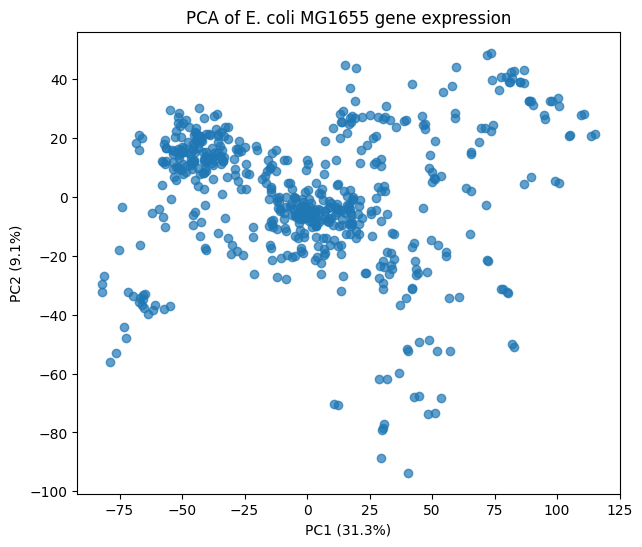

In [39]:
plt.figure(figsize=(7, 6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    alpha=0.7
)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA of E. coli MG1655 gene expression")

plt.show()

In [40]:
pca_df = pca_df.merge(
    mg1655_sample_conditions,
    left_index=True,
    right_on="unique_identifier"
)

In [41]:
pca_df.shape

(586, 61)

In [42]:
pca_df[
    ["unique_identifier", "PC1", "PC2", "project_name", "condition", "replicate_id"]
].head()

,unique_identifier,PC1,PC2,project_name,condition,replicate_id
0,pmg_wt_1,-3.423831,-6.718280,pan_fur,WT,1
1,pmg_wt_10,30.935421,-23.882446,in_house_2,stationary,2
2,pmg_wt_100,31.665043,30.810781,single_nutrient_perturbation,Uridine_NH4Cl,2
3,pmg_wt_101,105.307106,21.025165,single_nutrient_perturbation,Glucose_L-Ornithine,1
4,pmg_wt_102,104.915276,20.844225,single_nutrient_perturbation,Glucose_L-Ornithine,2


In [43]:
pca_df["project_name"].value_counts()

project_name
single_nutrient_perturbation    322
pilot-antibiotICA                40
AntibiotICA                      30
ICA                              28
stationary-TRN                   22
Two Component Systems            22
in_house_2                       16
Electric Coli                    13
RPO                               8
yTF 3                             8
Miscellaneous #2                  8
yTF                               6
Omics                             6
Nac/NtrC                          6
DDB_PD_038_AMBR                   6
yTF 5                             5
Fur                               4
MinSpan                           4
Cra/Crp                           4
OxyR ALE                          4
Misc                              2
EEP                               2
Crp ARs                           2
OmpR                              2
Oxidative                         2
pDNA                              2
RpoB Knock-in                     2
Control        

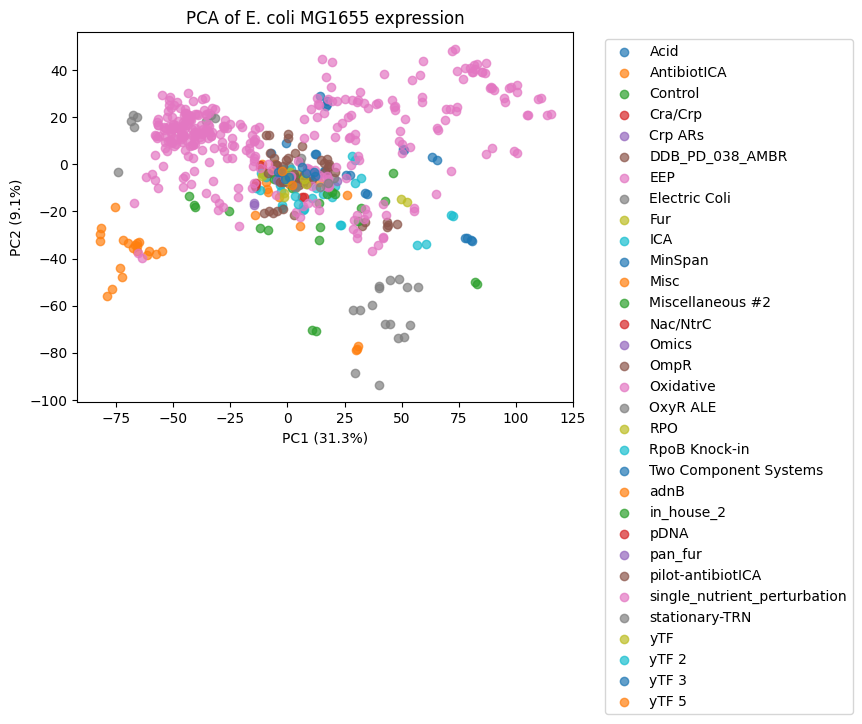

In [44]:
for project, group in pca_df.groupby("project_name"):
    plt.scatter(
        group["PC1"],
        group["PC2"],
        label=project,
        alpha=0.7
    )

plt.xlabel("PC1 (31.3%)")
plt.ylabel("PC2 (9.1%)")
plt.title("PCA of E. coli MG1655 expression")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

In [45]:
pca_df["condition"].nunique()

281

In [46]:
pca_df["condition"].value_counts()

condition
wt_glc                         18
wt_ph5                          4
wt_lb                           4
wt_glc_24hr                     3
ebk_hnq2_biod                   3
                               ..
Supp_Cysteine_(2mM)             2
Supp_Cytosine_(10mM)            2
Supp_D-Saccharic acid_(2mM)     2
Supp_D-Galactose_(2mM)          2
Cytidine_NH4Cl                  2
Name: count, Length: 281, dtype: int64

In [47]:
nutrient_pca = pca_df[
    pca_df["project_name"] == "single_nutrient_perturbation"
]

nutrient_pca["condition"].value_counts()

condition
Uridine_NH4Cl                        2
Supp_Aspartic acid_(2mM)             2
Supp_Pyruvic acid_(2mM)              2
Supp_N-Acetyl-D-Glucosamine_(2mM)    2
Supp_D-Glucose-6-Phosphate_(2mM)     2
                                    ..
Supp_Tryptophan_(2mM)                2
Supp_Alanine_(2mM)                   2
Supp_Valine_(2mM)                    2
Supp_Alanine_(10mM)                  2
Cytidine_NH4Cl                       2
Name: count, Length: 161, dtype: int64

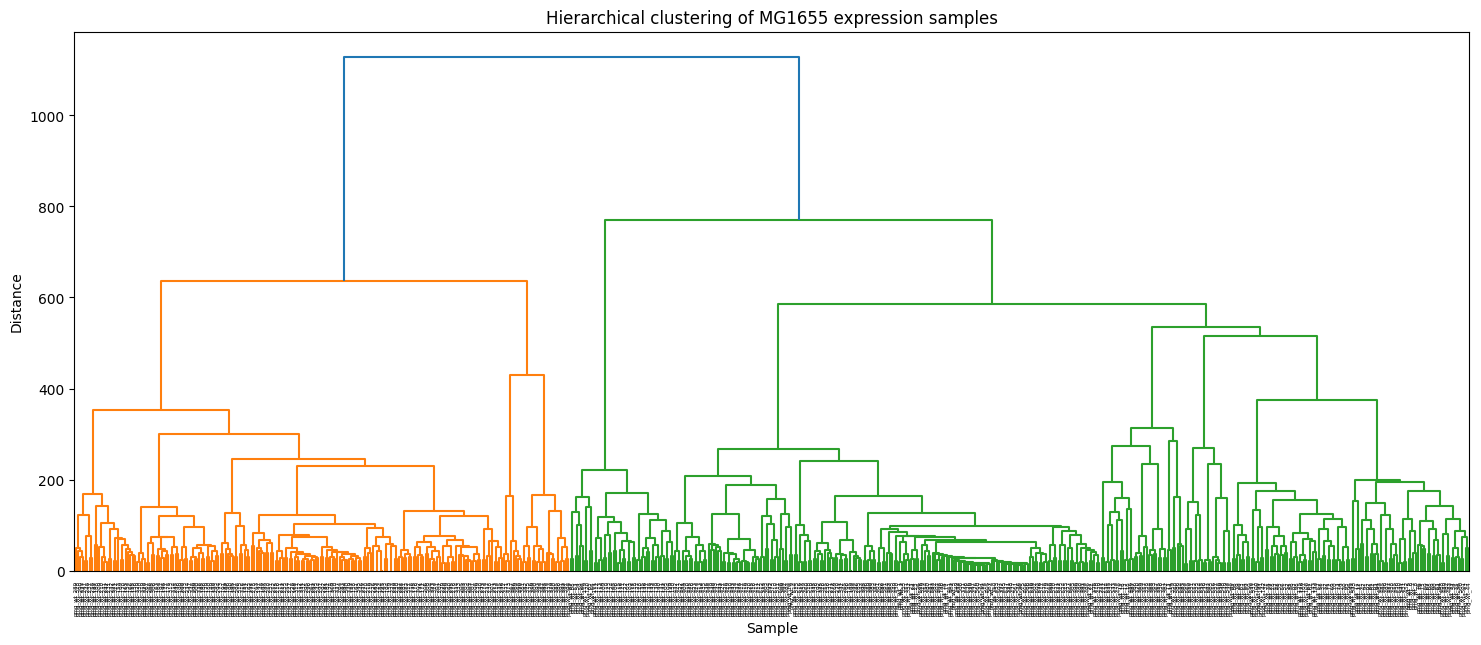

In [48]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Z = linkage(X, method="ward")

plt.figure(figsize=(18, 7))

dendrogram(
    Z,
    labels=X.index,
    leaf_rotation=90,
    leaf_font_size=4
)

plt.xlabel("Sample")
plt.ylabel("Distance")
plt.title("Hierarchical clustering of MG1655 expression samples")

plt.show()

In [49]:
pca = PCA(n_components=50)
X_pca = pca.fit_transform(X)
print(X_pca.shape)

(586, 50)


In [50]:
#create KNN graph
from sklearn.neighbors import kneighbors_graph

knn = kneighbors_graph(
    X_pca,
    n_neighbors=15,
    mode="connectivity",
    include_self=False
)

knn

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 8790 stored elements and shape (586, 586)>

In [51]:
# transform into igraph
import igraph as ig

sources, targets = knn.nonzero()

edges = list(zip(sources, targets))

g = ig.Graph(
    n=X.shape[0],
    edges=edges,
    directed=False
)

g.simplify()

In [52]:
import leidenalg

In [53]:
#leiden clustering 
partition = leidenalg.find_partition(
    g,
    leidenalg.RBConfigurationVertexPartition,
    resolution_parameter=0.5,
    seed=42
)

clusters = partition.membership


In [54]:
pd.Series(clusters).value_counts().sort_index()

0    178
1    101
2     95
3     92
4     63
5     37
6     20
Name: count, dtype: int64

In [55]:
metadata = mg1655_sample_conditions.copy()

metadata["leiden"] = pd.Categorical(
    [str(x) for x in clusters]
)

In [56]:
import umap

reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.5,
    random_state=42
)

X_umap = reducer.fit_transform(X_pca)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [57]:
metadata["UMAP1"] = X_umap[:, 0]
metadata["UMAP2"] = X_umap[:, 1]

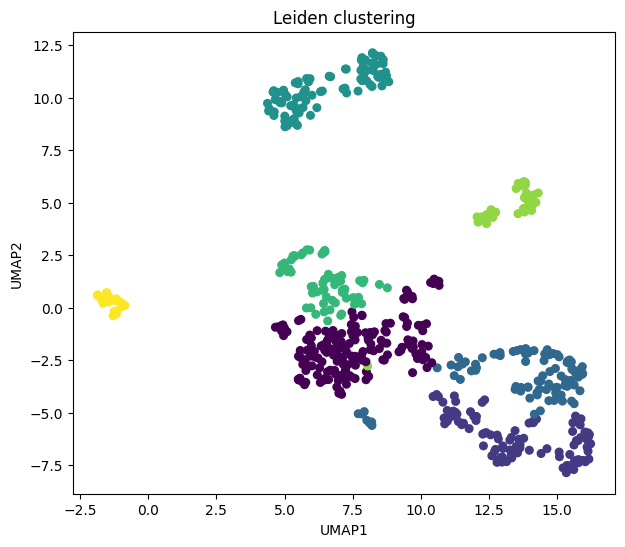

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(
    metadata["UMAP1"],
    metadata["UMAP2"],
    c=metadata["leiden"].astype(int),
    s=30
)

plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.title("Leiden clustering")

plt.show()

In [59]:
pd.crosstab(
    metadata["leiden"],
    metadata["project_name"],
    normalize="index"
).round(2)

project_name,Acid,AntibiotICA,Control,Cra/Crp,Crp ARs,DDB_PD_038_AMBR,EEP,Electric Coli,Fur,ICA,...,in_house_2,pDNA,pan_fur,pilot-antibiotICA,single_nutrient_perturbation,stationary-TRN,yTF,yTF 2,yTF 3,yTF 5
leiden,,,,,,,,,,,,,,,,,,,,,
0,0.01,0.06,0.01,0.02,0.01,0.01,0.01,0.03,0.02,0.11,...,0.08,0.00,0.01,0.02,0.12,0.11,0.03,0.01,0.04,0.01
1,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
2,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.08,0.00,0.00,...,0.00,0.00,0.00,0.00,0.92,0.00,0.00,0.00,0.00,0.00
3,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00
4,0.00,0.00,0.00,0.00,0.00,0.06,0.00,0.00,0.00,0.13,...,0.03,0.03,0.00,0.00,0.32,0.03,0.00,0.00,0.00,0.05
5,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00
6,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


### calculate the degree for each protein

In [60]:
G = nx.from_pandas_edgelist(
    mg1655_network_interactions,
    source="gene1",
    target="gene2"
)

degree_df = pd.DataFrame(
    G.degree(),
    columns=["gene_id", "degree"]
)

degree_df

,gene_id,degree
0,b0002,11
1,b0436,112
2,b0473,119
3,b1945,109
4,b2926,78
...,...,...
3168,b4244,1
3169,b4319,3
3170,b4334,1
3171,b4363,1


### merge the gene expression with degree

In [61]:
mg1655_data = mg1655_expression.merge(
    degree_df,
    on="gene_id",
    how="left"
)

In [12]:
mg1655_data

,gene_id,pmg_wt_1,pmg_wt_10,pmg_wt_100,pmg_wt_101,pmg_wt_102,pmg_wt_103,pmg_wt_104,pmg_wt_105,pmg_wt_106,...,pmg_wt_91,pmg_wt_92,pmg_wt_93,pmg_wt_94,pmg_wt_95,pmg_wt_96,pmg_wt_97,pmg_wt_98,pmg_wt_99,degree
0,b0001,-0.508210,1.780489,0.722802,1.476414,2.383642,4.112133,3.730746,-0.196990,-0.997967,...,-2.815976,-3.011560,-2.576984,-1.262916,1.347708,1.841094,-0.552674,-1.566595,1.227660,NaN
1,b0002,0.182318,-0.197608,-0.822170,-1.536439,-1.543038,-0.771767,-0.773725,1.272620,1.125288,...,-0.522540,-0.558576,-2.008627,-2.383164,-0.117049,-0.147349,-1.088351,-0.983296,-0.554786,11.0
2,b0003,0.392437,-0.100001,0.091438,-0.916514,-0.981507,-0.336039,-0.183540,1.444999,1.716814,...,-0.092215,-0.158409,-1.713275,-1.931230,0.119124,0.021417,-0.765254,-0.525073,0.147829,NaN
3,b0004,-0.096891,-0.426017,-0.045651,-1.383575,-1.366994,-0.585717,-0.474251,1.103980,1.477590,...,0.171979,0.055813,-1.294275,-1.648703,0.012734,-0.067448,-0.590740,-0.351376,-0.105335,11.0
4,b0005,-0.181680,-1.168733,-0.470824,-2.116620,-2.018665,-1.132125,-1.144595,0.609102,0.043054,...,-0.125883,-0.228694,-1.567951,-1.622031,-0.906826,-0.701478,-1.423720,-1.224787,-0.746430,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4300,b4820,1.458344,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
4301,b4821,-0.822529,1.806504,-2.174971,-2.034266,-3.664961,-6.407322,-6.407322,-0.252035,-2.402241,...,1.066561,0.871170,1.255993,1.516656,-1.903401,-2.033700,-6.407322,-3.318284,-2.658700,NaN
4302,b4822,-0.922037,0.000000,3.155315,2.921023,1.534667,1.915924,2.034781,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,2.100396,1.608410,1.808631,2.662677,NaN
4303,b4823,1.640840,0.000000,2.046412,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN


In [62]:
mg1655_data["degree"].notna().sum()

np.int64(3173)

In [63]:
mg1655_data["degree"].isna().sum()

np.int64(1132)

In [64]:
mg1655_data["degree"].notna().sum() + \
mg1655_data["degree"].isna().sum()

np.int64(4305)

In [66]:
mg1655_data.to_csv(
    "mg1655_expression_with_degree.csv",
    index=False
)